
--- Caso 1: C1=1uF, C2=1uF ---
Energía inicial (Ui): 0.5000 uJ
Energía final teórica (Uf): 0.2500 uJ
Diferencia teórica Ui - Uf: 0.2500 uJ
Energía disipada en R (integral numérica de I^2*R): 0.2498 uJ
--> Comprobación: Ui - disipada = 0.2502 uJ

--- Caso 2: C1=10uF, C2=1uF ---
Energía inicial (Ui): 0.0500 uJ
Energía final teórica (Uf): 0.0455 uJ
Diferencia teórica Ui - Uf: 0.0045 uJ
Energía disipada en R (integral numérica de I^2*R): 0.0045 uJ
--> Comprobación: Ui - disipada = 0.0455 uJ


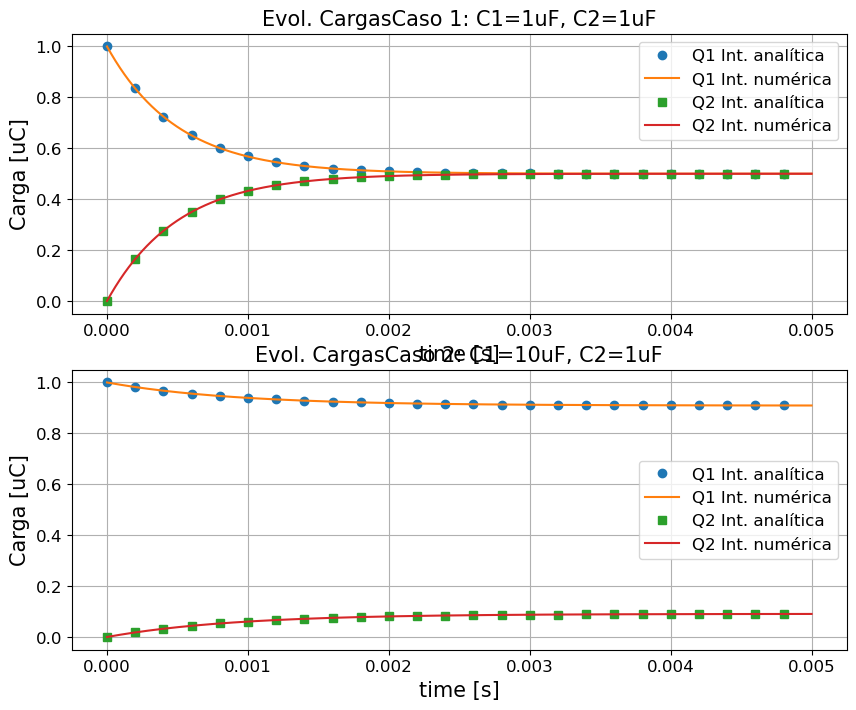

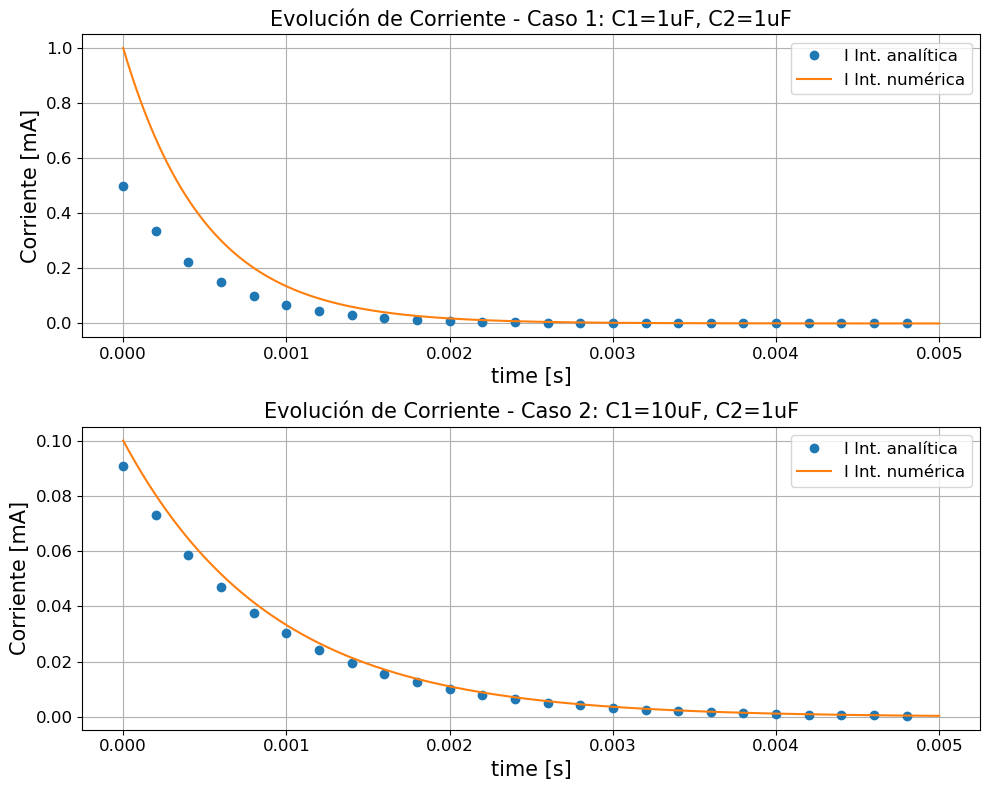

In [5]:
# -*- coding: utf-8 -*-
"""
Created on Sat May 13 10:32:59 2023
@author: Cristian
"""
############################# Integración numérica ###########################
import numpy as np
import matplotlib.pyplot as plt

# Creamos dos ventanas de figuras: una para Cargas y otra para Corriente
fig_q, ax_q = plt.subplots(2, 1, figsize=(10, 8))
fig_i, ax_i = plt.subplots(2, 1, figsize=(10, 8))

############# parámetros ####################################################

Q0 = 1e-6      # Carga inicial en C1 [C]
time_i = 0
R = 1000
step = 1e-6    # Paso de tiempo [s] (Más chico que en el ejemplo RC porque el tau es ~0.5ms)
time = np.arange(0, 0.005, step) # Simulamos hasta 5ms

# Evaluamos los dos casos del trabajo práctico
casos = [
    {'C1': 1e-6, 'C2': 1e-6, 'label': 'Caso 1: C1=1uF, C2=1uF'},
    {'C1': 10e-6, 'C2': 1e-6, 'label': 'Caso 2: C1=10uF, C2=1uF'}
]

#################### Ecuaciones #############################################

# Ecuación integrada analíticamente
def Q2_ana(t, q0, ti, r, c1, c2):
    tau = r * (c1 * c2) / (c1 + c2)
    Q2f = q0 * c2 / (c1 + c2)
    return Q2f * (1 - np.exp(-(t - ti)/tau))

def I_ana(t, q0, ti, r, c1, c2):
    tau = r * (c1 * c2) / (c1 + c2)
    I0 = q0 / (r * (c1 + c2))
    return I0 * np.exp(-(t - ti)/tau)

# Ecuación a integrar numéricamente (Euler explícito)
# dQ2/dt = I(t) = ( V1 - V2 ) / R = ( (Q0-Q2)/C1 - Q2/C2 ) / R
def Q2_num(Dt, q2, r, c1, c2, q0):
    I = ((q0 - q2)/c1 - q2/c2) / r
    q2_next = I * Dt + q2
    return q2_next, I

###############################################################################

for idx, caso in enumerate(casos):
    C1 = caso['C1']
    C2 = caso['C2']
    label = caso['label']
    
    Q2_analitica, Q2_numerica, I_analitica, I_numerica = [], [], [], []
    
    # 1. Solución Analítica
    for ts in time:
        Q2_analitica.append(Q2_ana(ts, Q0, time_i, R, C1, C2))
        I_analitica.append(I_ana(ts, Q0, time_i, R, C1, C2))
        
    # 2. Solución Numérica
    Q2 = 0 # Condición inicial: C2 descargado
    for ts in time:
        Q2_next, I = Q2_num(step, Q2, R, C1, C2, Q0)
        Q2_numerica.append(Q2)
        I_numerica.append(I)
        Q2 = Q2_next # Actualizamos para el próximo paso
        
    # Convertimos a arrays de numpy
    Q2_analitica = np.array(Q2_analitica)
    Q2_numerica = np.array(Q2_numerica)
    I_analitica = np.array(I_analitica)
    I_numerica = np.array(I_numerica)
    
    # Q1 se deduce de la conservación de carga
    Q1_analitica = Q0 - Q2_analitica
    Q1_numerica = Q0 - Q2_numerica

    ############################## plots ######################################
    
    ax = ax_q[idx]
    # markevery=200 evita graficar todos los puntos y saturar el gráfico
    ax.plot(time, Q1_analitica*1e6, 'o', markevery=200, label='Q1 Int. analítica')
    ax.plot(time, Q1_numerica*1e6, '-', label='Q1 Int. numérica')
    ax.plot(time, Q2_analitica*1e6, 's', markevery=200, label='Q2 Int. analítica')
    ax.plot(time, Q2_numerica*1e6, '-', label='Q2 Int. numérica')

    ax.set_title(f'Evol. Cargas{label}', fontsize=15)
    ax.legend(fontsize=12)
    ax.set_xlabel('time [s]', fontsize=15)
    ax.set_ylabel('Carga [uC]', fontsize=15)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid()

    ax_i_plot = ax_i[idx]
    ax_i_plot.plot(time, I_analitica*1e3, 'o', markevery=200, label='I Int. analítica')
    ax_i_plot.plot(time, I_numerica*1e3, '-', label='I Int. numérica')

    ax_i_plot.set_title(f'Evolución de Corriente - {label}', fontsize=15)
    ax_i_plot.legend(fontsize=12)
    ax_i_plot.set_xlabel('time [s]', fontsize=15)
    ax_i_plot.set_ylabel('Corriente [mA]', fontsize=15)
    ax_i_plot.tick_params(axis='both', labelsize=12)
    ax_i_plot.grid()
    
    ############################## Energías ###################################
    U_inicial = (Q0**2) / (2*C1)
    
    # Demostración numérica: Energía disipada = integral de I^2 * R dt
    energia_disipada = np.trapz(I_numerica**2 * R, time)
    
    Q1f = Q0 * C1 / (C1 + C2)
    Q2f = Q0 * C2 / (C1 + C2)
    U_final = (Q1f**2)/(2*C1) + (Q2f**2)/(2*C2)
    
    print(f"\n--- {label} ---")
    print(f"Energía inicial (Ui): {U_inicial*1e6:.4f} uJ")
    print(f"Energía final teórica (Uf): {U_final*1e6:.4f} uJ")
    print(f"Diferencia teórica Ui - Uf: {(U_inicial - U_final)*1e6:.4f} uJ")
    print(f"Energía disipada en R (integral numérica de I^2*R): {energia_disipada*1e6:.4f} uJ")
    print(f"--> Comprobación: Ui - disipada = {(U_inicial - energia_disipada)*1e6:.4f} uJ")

plt.tight_layout()
plt.show()

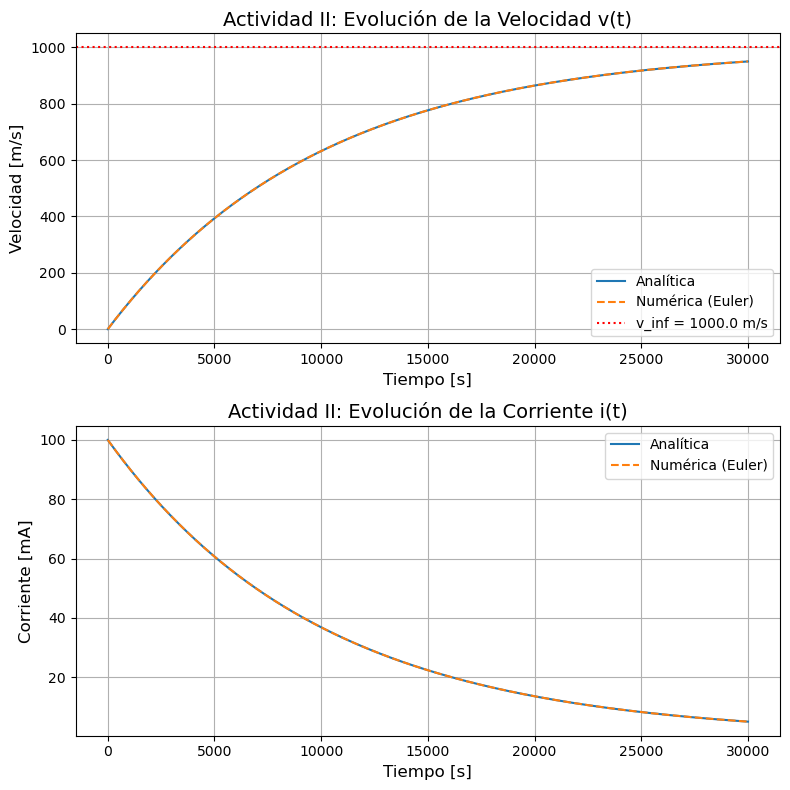

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parámetros Actividad II ---
V0 = 10         # V
L = 0.1         # m (10 cm)
m = 0.01        # kg (10 gr)
R = 100         # Ohm
# 1 kOe = 1000 Oe. 1 Oe = 1000/(4*pi) A/m. B = mu0 * H = 0.1 T
B = 0.1         # T 

# Condiciones iniciales
v0 = 0
step = 1.0      # s (Paso de tiempo grande porque el proceso es lento)
time = np.arange(0, 30000, step) # Simulamos hasta 30000 s (3 veces tau)

# --- Ecuaciones ---
# Analíticas
v_inf = V0 / (B * L)
tau = (m * R) / (B * L)**2
def v_analitica(t):
    return v_inf * (1 - np.exp(-t / tau))
def i_analitica(t):
    return (V0 / R) * np.exp(-t / tau)

# Numérica (Euler)
# m * dv/dt = i * L * B  -->  m * dv/dt = ((V0 - B*L*v)/R) * L * B
def v_num(Dt, v):
    i = (V0 - B * L * v) / R
    dvdt = (i * L * B) / m
    return v + dvdt * Dt

# --- Simulación ---
v_ana = v_analitica(time)
i_ana = i_analitica(time)

v_num_arr = []
v = 0
for ts in time:
    v_num_arr.append(v)
    v = v_num(step, v)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8))

# Plot 3: Velocidad
ax1.plot(time, v_ana, '-', label='Analítica')
ax1.plot(time, v_num_arr, '--', label='Numérica (Euler)')
ax1.set_title('Actividad II: Evolución de la Velocidad v(t)', fontsize=14)
ax1.set_xlabel('Tiempo [s]', fontsize=12)
ax1.set_ylabel('Velocidad [m/s]', fontsize=12)
ax1.axhline(y=v_inf, color='r', linestyle=':', label=f'v_inf = {v_inf:.1f} m/s')
ax1.legend()
ax1.grid()

# Plot 4: Corriente
i_num_arr = [(V0 - B * L * vi) / R for vi in v_num_arr]
ax2.plot(time, i_ana * 1000, '-', label='Analítica')
ax2.plot(time, np.array(i_num_arr) * 1000, '--', label='Numérica (Euler)')
ax2.set_title('Actividad II: Evolución de la Corriente i(t)', fontsize=14)
ax2.set_xlabel('Tiempo [s]', fontsize=12)
ax2.set_ylabel('Corriente [mA]', fontsize=12)
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()
